# 09 · Stretch goals: extra pairs and the results dashboard

The proposal's stretch goals were hidden Markov model regimes, Transformer forecasters, longer horizons, additional pairs and an interactive results dashboard. The first three are in notebook 08. This notebook covers the last two:

1. **Extra pairs:** EUR/GBP, a cross with no dollar leg, and USD/INR, a managed emerging-market currency, through the same walk-forward tests as the core pairs (`src/fxml/extra_pairs.py`, `scripts/build_extra_pairs.py`, `scripts/run_extra_pairs.py`). They stay out of every core table, regime model and factor, so nothing earlier changes.
2. **The results dashboard:** every result in one place, as a static page and a Streamlit app (`scripts/build_dashboard.py`, `dashboard/app.py`).

USD/INR has no free intraday data, so its prices are the Federal Reserve's noon rates. It therefore has no realized variance (no volatility task, no intraday features), and because a noon rate is fixed five hours before the 17:00 close that dates every other input, it takes those inputs from the previous trading day.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fxml import viz
from fxml.config import load_config

cfg = load_config()
viz.apply_style()
tables = cfg.paths.reports / "tables"
extra = {t: pd.read_csv(tables / f"extra_pairs_{t}.csv") for t in ("volatility", "direction", "returns")}
core = {t: pd.read_csv(tables / f"ml_{t}.csv") for t in ("volatility", "direction", "returns")}
check = pd.read_csv(tables / "extra_data_check.csv", index_col=0)
backtest = pd.read_csv(tables / "extra_pairs_backtest.csv")
var = pd.read_csv(tables / "extra_pairs_var.csv")
label = {p: f"{p[:3]}/{p[3:]}" for p in [*cfg.pairs, *cfg.extra_pairs]}
pd.set_option("display.precision", 4)

## 1. Data

EUR/GBP's noon prices are checked against the H.10 rate implied by the two dollar legs (USD per EUR divided by USD per GBP), including the weeks when US and European clocks change on different dates. USD/INR's prices are the H.10 rates themselves; its coverage counts only US business days, so holidays show as missing.

In [2]:
check.loc[:, ["first", "last", "coverage_pct", "missing", "partial_days", "return_corr",
              "return_corr_clock_gap", "mean_abs_level_gap_pct"]].T

,EURGBP,USDINR
first,2006-01-03,2006-01-03
last,2026-10-23,2026-10-23
coverage_pct,100.0,96.5549
missing,0,186
partial_days,169,0
return_corr,0.997,NaN
return_corr_clock_gap,0.9932,NaN
mean_abs_level_gap_pct,0.0125,NaN


## 2. Volatility: does the machine learning edge carry over to a cross?

QLIKE of each model relative to HAR-RV (negative is better), EUR/GBP next to the seven core pairs.

In [3]:
def gain(table, pairs):
    rows = table[table.pair.isin(pairs)].pivot(index="pair", columns="model", values="qlike")
    return rows.drop(columns="baseline_har").div(rows["baseline_har"], axis=0) - 1

models = ["baseline_garch", "ridge", "random_forest", "lightgbm", "mlp"]
both = pd.concat([gain(core["volatility"], cfg.pairs)[models], gain(extra["volatility"], ["EURGBP"])[models]])
both.index = both.index.map(label)
(100 * both).round(1).rename(columns=lambda m: m.removeprefix("baseline_"))

model,garch,ridge,random_forest,lightgbm,mlp
pair,,,,,
AUD/USD,26.0,-5.9,-6.8,-9.8,-7.3
EUR/USD,16.6,-1.3,-4.1,-6.5,-3.3
GBP/USD,24.4,1.3,-3.6,-5.3,1.2
NZD/USD,25.6,-4.3,-4.2,-5.9,-6.6
USD/CAD,18.9,-3.8,-2.9,-6.9,-3.9
USD/CHF,34.1,5.8,10.8,-3.6,-5.0
USD/JPY,15.6,-1.3,-3.7,-6.4,-1.1
EUR/GBP,36.3,-1.3,0.1,-1.2,1.6


In [4]:
dm = extra["volatility"].set_index(["pair", "model"])[["qlike", "dm_vs_baseline_har", "dm_p_vs_baseline_har"]]
dm.loc["EURGBP"].loc[["baseline_har", "ridge", "lightgbm", "random_forest", "mlp"]]

,qlike,dm_vs_baseline_har,dm_p_vs_baseline_har
model,,,
baseline_har,0.1220,NaN,NaN
ridge,0.1204,-0.6205,0.5350
lightgbm,0.1205,-0.4153,0.6780
random_forest,0.1221,0.0884,0.9296
mlp,0.1239,0.4507,0.6522


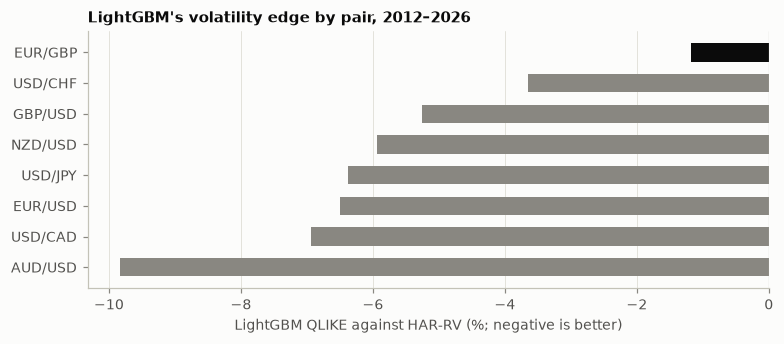

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 3.2))
values = 100 * both["lightgbm"].sort_values()
colors = [viz.INK if p == "EUR/GBP" else viz.INK_MUTED for p in values.index]
ax.barh(values.index, values, color=colors, height=0.6)
ax.axvline(0, color=viz.BASELINE, lw=0.8)
ax.set_xlabel("LightGBM QLIKE against HAR-RV (%; negative is better)")
ax.set_title("LightGBM's volatility edge by pair, 2012–2026")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save(fig, "extra_volatility_vs_har")

## 3. Direction

AUC of the up/down probability, the Pesaran–Timmermann test of the calls (p < 0.05 means they beat chance) and the Diebold–Mariano test of the Brier score against the frequency of up days.

In [6]:
cols = ["roc_auc", "accuracy", "pt_p", "dm_vs_baseline_frequency", "dm_p_vs_baseline_frequency", "ece"]
extra["direction"][extra["direction"].pair != "average"].set_index(["pair", "model"])[cols]

roc_auc  accuracy        pt_p  \
pair   model                                                 
EURGBP baseline_frequency     0.4915    0.5085  3.9883e-01   
       baseline_persistence   0.4865    0.4860  9.6019e-01   
       lightgbm               0.5090    0.5100  1.1844e-01   
       logistic_l2            0.4999    0.4954  7.7974e-01   
       mlp                    0.4967    0.5048  4.6328e-01   
       naive_bayes            0.4999    0.4965  6.2452e-01   
       random_forest          0.5098    0.5046  3.3088e-01   
USDINR baseline_frequency     0.4913    0.5126         NaN   
       baseline_persistence   0.4740    0.4772  9.9758e-01   
       lightgbm               0.5372    0.5363  1.2520e-05   
       logistic_l2            0.5200    0.5063  5.9508e-01   
       mlp                    0.5138    0.5158  1.0429e-01   
       naive_bayes            0.5109    0.5158  1.0329e-01   
       random_forest          0.5356    0.5315  1.9450e-04   

                             dm_vs_baseline_frequency  \
pair   model                                            
EURGBP baseline_frequency                         NaN   
       baseline_persistence                   32.5851   
       lightgbm                                2.9054   
       logistic_l2                             1.0841   
       mlp                                     1.8407   
       naive_bayes                             4.1817   
       random_forest                           0.6524   
USDINR baseline_frequency                         NaN   
       baseline_persistence                   32.8677   
       lightgbm                                0.4190   
       logistic_l2                            -0.1518   
       mlp                                     0.7773   
       naive_bayes                             2.7533   
       random_forest                          -1.2843   

                             dm_p_vs_baseline_frequency     ece  
pair   model                                                     
EURGBP baseline_frequency                           NaN  0.0178  
       baseline_persistence                 8.4106e-206  0.5133  
       lightgbm                              3.6884e-03  0.0406  
       logistic_l2                           2.7838e-01  0.0295  
       mlp                                   6.5742e-02  0.0223  
       naive_bayes                           2.9578e-05  0.0462  
       random_forest                         5.1416e-01  0.0284  
USDINR baseline_frequency                           NaN  0.0178  
       baseline_persistence                 4.0841e-208  0.5107  
       lightgbm                              6.7524e-01  0.0377  
       logistic_l2                           8.7937e-01  0.0273  
       mlp                                   4.3702e-01  0.0250  
       naive_bayes                           5.9291e-03  0.0412  
       random_forest                         1.9910e-01  0.0247

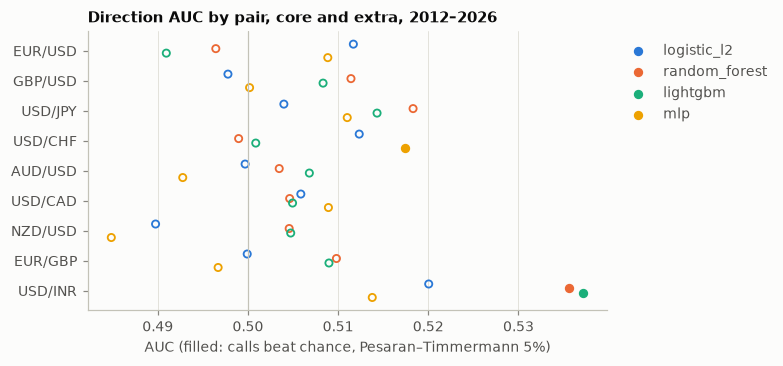

In [7]:
auc = pd.concat([core["direction"][core["direction"].pair.isin(cfg.pairs)],
                 extra["direction"][extra["direction"].pair.isin(cfg.extra_pairs)]])
auc = auc[auc.model.isin(["logistic_l2", "random_forest", "lightgbm", "mlp"])]
fig, ax = plt.subplots(figsize=(7.2, 3.4))
order = [label[p] for p in [*cfg.pairs, *cfg.extra_pairs]]
for i, model in enumerate(["logistic_l2", "random_forest", "lightgbm", "mlp"]):
    rows = auc[auc.model == model].set_index("pair")
    y = [order.index(label[p]) + (i - 1.5) * 0.15 for p in rows.index]
    significant = rows.pt_p < 0.05
    ax.scatter(rows.roc_auc[~significant], np.array(y)[~significant.values], s=22,
               facecolors="none", edgecolors=viz.CATEGORICAL[i], linewidths=1.2)
    ax.scatter(rows.roc_auc[significant], np.array(y)[significant.values], s=26,
               color=viz.CATEGORICAL[i], label=model)
ax.axvline(0.5, color=viz.BASELINE, lw=0.8)
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_xlabel("AUC (filled: calls beat chance, Pesaran–Timmermann 5%)")
ax.set_title("Direction AUC by pair, core and extra, 2012–2026")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save(fig, "extra_direction_auc")

## 4. Returns

Out-of-sample R² against a zero forecast.

In [8]:
extra["returns"][extra["returns"].pair != "average"].pivot(index="model", columns="pair", values="r2_oos")

pair,EURGBP,USDINR
model,,
baseline_arima,-0.0020,0.0003
baseline_mean,-0.0005,0.0010
baseline_zero,0.0000,0.0000
lightgbm,-0.0196,-0.0069
mlp,-0.0015,-0.0012
ridge,-0.0046,-0.0028


## 5. Trading

Each pair on its own, net of costs (one paisa of spread for USD/INR, 1.2 pips for EUR/GBP), unit size and EWMA volatility targeting.

In [9]:
keep = ["long", "carry", "momentum", "logistic_l2", "random_forest", "lightgbm", "lightgbm_confident", "mlp"]
bt = backtest[backtest.signal.isin(keep) & backtest.sizing.isin(["unit", "vt_ewma"])]
bt.pivot_table(index="signal", columns=["pair", "sizing"], values="sharpe").loc[keep].round(2)

pair               EURGBP         USDINR        
sizing               unit vt_ewma   unit vt_ewma
signal                                          
long                -0.08   -0.15  -0.09    0.08
carry                0.11    0.20   0.09   -0.10
momentum            -0.14   -0.18   0.05    0.24
logistic_l2         -0.16   -0.32  -0.23   -0.48
random_forest       -0.15   -0.26   0.10    0.03
lightgbm            -0.08   -0.13   0.31    0.06
lightgbm_confident  -0.18   -0.20   0.28    0.05
mlp                  0.11    0.05  -0.04   -0.23

In [10]:
bt[(bt.sizing == "unit")].set_index(["pair", "signal"]).loc[:, ["ann_return", "sharpe", "p_value", "sharpe_2x_costs"]].round(3)

,,ann_return,sharpe,p_value,sharpe_2x_costs
pair,signal,,,,
EURGBP,carry,0.008,0.109,0.667,0.108
USDINR,carry,0.006,0.087,0.726,0.087
EURGBP,lightgbm,-0.006,-0.079,0.749,-0.279
USDINR,lightgbm,0.020,0.314,0.225,0.074
EURGBP,lightgbm_confident,-0.009,-0.177,0.474,-0.380
USDINR,lightgbm_confident,0.012,0.277,0.318,0.025
EURGBP,logistic_l2,-0.012,-0.164,0.502,-0.349
USDINR,logistic_l2,-0.015,-0.231,0.367,-0.351
EURGBP,long,-0.005,-0.078,0.758,-0.078


## 6. Value at Risk

99% one-day Value at Risk from each variance forecast.

In [11]:
var.pivot_table(index=["model", "method"], columns=["pair", "side"], values="rate").round(4)

pair                       EURGBP          USDINR        
side                         long   short    long   short
model              method                                
baseline_ewma      fhs     0.0142  0.0134  0.0125  0.0133
                   normal  0.0165  0.0195  0.0136  0.0246
baseline_garch     fhs     0.0123  0.0131  0.0119  0.0119
                   normal  0.0123  0.0165  0.0096  0.0174
baseline_gjr_garch fhs     0.0126  0.0126     NaN     NaN
                   normal  0.0126  0.0167     NaN     NaN
baseline_har       fhs     0.0131  0.0123     NaN     NaN
                   normal  0.0081  0.0131     NaN     NaN
baseline_naive     fhs     0.0131  0.0126     NaN     NaN
                   normal  0.0120  0.0190     NaN     NaN
lightgbm           fhs     0.0137  0.0120     NaN     NaN
                   normal  0.0075  0.0114     NaN     NaN
mlp                fhs     0.0123  0.0134     NaN     NaN
                   normal  0.0078  0.0117     NaN     NaN
random_forest      fhs     0.0128  0.0128     NaN     NaN
                   normal  0.0081  0.0123     NaN     NaN
ridge              fhs     0.0123  0.0123     NaN     NaN
                   normal  0.0081  0.0114     NaN     NaN

## 7. Findings

- **Data:** EUR/GBP's noon prices follow the implied H.10 cross with a return correlation of about 0.997, and 0.993 in the weeks when the US and European clocks disagree, so the HistData clock handling holds for a cross as well.
- **Volatility:** on EUR/GBP the learning models only match HAR-RV. LightGBM's QLIKE is about 1% lower and ridge's about 1% lower, neither significant, against a 6.1% gain significant on 5 of the 7 core pairs. The one-day volatility edge does not carry over to the cross.
- **Direction:** EUR/GBP is at chance like the core pairs. USD/INR is the one pair where up/down calls beat chance: LightGBM (AUC 0.537) and the random forest (0.536) pass Pesaran–Timmermann at p < 0.001, though neither improves the Brier score significantly on the frequency of up days.
- **Trading:** that predictability does not become a significant profit. LightGBM's USD/INR signal earns a Sharpe of 0.31 after costs (p = 0.23), and carry earns 0.11 on EUR/GBP and 0.09 on USD/INR, neither significant.
- **Caveat:** USD/INR's price is one indicative quote taken after India's onshore market has closed, so part of its predictability may be slow adjustment in a thin quote rather than a tradable edge. Its mild daily mean reversion (lag-1 autocorrelation about −0.03 since 2012) is not enough to explain it.

## 8. The results dashboard

`uv run python scripts/build_dashboard.py` collects every result into `reports/dashboard/data.json` and writes `reports/dashboard.html`, one self-contained page that opens offline. It has three views:

- **Verdicts:** every model against its benchmark, pair by pair, as a scorecard of triangles (filled = significant, up = better), next to the five research questions with their tests and source tables. Selecting a cell opens the test behind it.
- **Explorer:** all scorecards, horizons, regimes, the backtest, Value at Risk, learning curves, calibration, features, the extra pairs and the data checks.
- **Present:** ten slides for the final presentation, moved with the arrow keys.

The same views run as a Streamlit app: `uv run --group dashboard streamlit run dashboard/app.py`.